# Baseline Model

## Load Required Libraries and Dataset

In [1]:
#Import Required Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from imblearn.over_sampling import SMOTE
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from imblearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
#Import data
df = pd.read_csv('../01_data/model_df.csv')
df.head()

,age,job,marital,education,default,housing,loan,contact,day,month,poutcome,y,contacted_before,balance_log,campaign_log,previous_log,age_bucket,balance_positive,long_campaign
0,58,management,married,tertiary,0,1,0,unknown,5,may,unknown,0,0,9.226607,0.693147,0.0,senior,1,0
1,44,technician,single,secondary,0,1,0,unknown,5,may,unknown,0,0,8.993427,0.693147,0.0,middle,1,0
2,33,entrepreneur,married,secondary,0,1,1,unknown,5,may,unknown,0,0,8.990068,0.693147,0.0,middle,1,0
3,47,blue-collar,married,unknown,0,1,0,unknown,5,may,unknown,0,0,9.161885,0.693147,0.0,middle,1,0
4,33,unknown,single,unknown,0,0,0,unknown,5,may,unknown,0,0,8.989943,0.693147,0.0,middle,1,0


## Logistic Regression Model

In [8]:
#Define numeric features that need to be scaled and categorical featurs that need OneHotEncoding
numeric_features = ['age', 'balance_log', 'previous_log']
categorical_features = [
    "job","education","marital","contact","poutcome", "day", "month","age_bucket"
]

#Create a preprocessing transformer variable
preprocessor = ColumnTransformer(
    transformers = [
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown = 'ignore'), categorical_features)
    ]
)

#Build the pipeline
pipeline_lr = Pipeline(steps = [
    ('preprocess', preprocessor),
    ('smote', SMOTE(random_state = 42)),
    ('classifier', LogisticRegression(random_state = 42))
])

In [9]:
#Split data
X = df.drop('y', axis = 1)
y = df['y']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42)

In [10]:
#Fit the pipeline on the training data
pipeline_lr.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'balance_log',
                                                   'previous_log']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['job', 'education',
                                                   'marital', 'contact',
                                                   'poutcome', 'day', 'month',
                                                   'age_bucket'])])),
                ('smote', SMOTE(random_state=42)),
                ('classifier', LogisticRegression(random_state=42))])

In [12]:
#Predict
y_pred = pipeline_lr.predict(X_test)

### Evaluation

Text(0.5, 23.52222222222222, 'Predicted label')

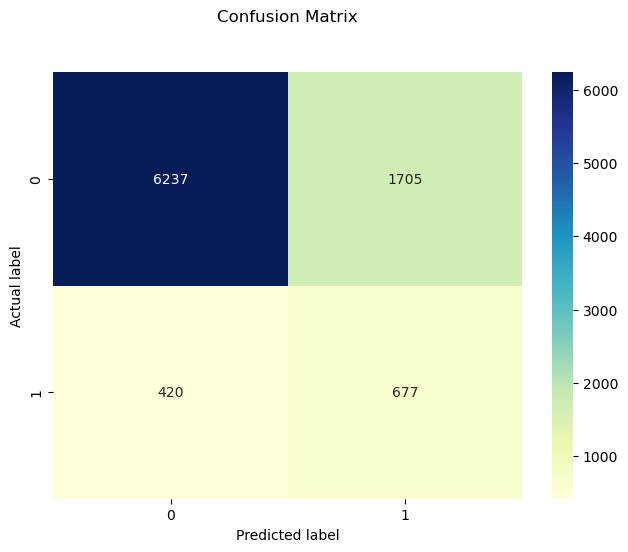

In [13]:
#Confusion Matrix
cnf_matrix = confusion_matrix(y_test, y_pred)

class_names = [0,1]
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)

#Create heatmap
sns.heatmap(pd.DataFrame(cnf_matrix), annot = True, cmap = "YlGnBu", fmt = 'g')
plt.tight_layout()
plt.title('Confusion Matrix', y = 1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')

**Commentary:**
* The confusion matrix shows that the model struggles with identifying actual subscribers (420 false negatives). This is to be expected due to the class imbalance within the model. However, it is important to reduce false negatives as missing potential subscribers could directly impact campaign success.

* The high number of true negatives (6237) shows the model is very good at identifying non-subscribers, but improving performance on theminority class is essential for a marketing-focused application.

In [14]:
target_names = ['no', 'yes']
print(classification_report(y_test, y_pred, target_names = target_names))

              precision    recall  f1-score   support

          no       0.94      0.79      0.85      7942
         yes       0.28      0.62      0.39      1097

    accuracy                           0.76      9039
   macro avg       0.61      0.70      0.62      9039
weighted avg       0.86      0.76      0.80      9039



**Commentary:**
* The classification report shows that there is a clear performance difference between the majority class ('no') and the minority class ('yes'). The model achieves high precision (0.94), recall (0.78), and F1-score (0.85) for the 'no' class meanin it is very effective at identifying customers who will not subscribe. However, this is expected for imbalanced datasets where the majority class dominates the learning process.
  
* For the minority class, performance is noticeably weaker. Precision is low (0.28), meaning many customers predicted as subscribers are actually non-subscribers. Recall is moderate (0.62), suggesting the model identifies some subscribers but still misses a large proportion. The low F1-score (0.39) reflects the difficulty the model has in learning this minority class, even after applying SMOTE.

* This imbalance in performance is important because missing actual subscribers (low precision and F1-score for class 1) means the bank fails to target customers who might have converted, reducing campaign effectiveness.

* Accuracy is 0.76 which alone is misleading in imbalanced datasets. The model performs well for the majority class but requires improvement to better detect potential subscribers.

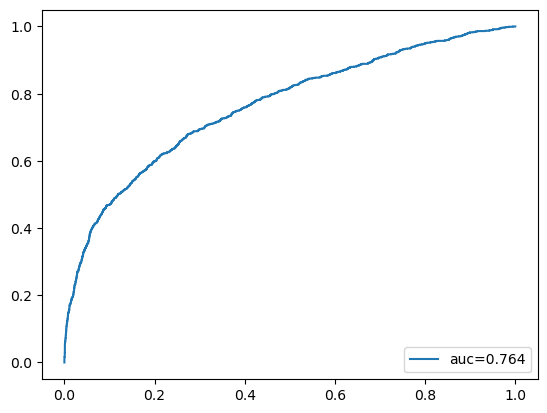

In [18]:
#ROC CURVE
y_pred_proba = pipeline_lr.predict_proba(X_test)[::,1]
fpr, tpr, _ = metrics.roc_curve(y_test, y_pred_proba)
auc = metrics.roc_auc_score(y_test, y_pred_proba)
plt.plot(fpr, tpr, label = "auc="+ str(round(auc,3)))
plt.legend(loc = 4)
plt.show()

**Commentary:**
* The ROC curve shows how well the model distinguishes between subscribers and non-subscribers across different probability threhsolds.
* The AUC score of 0.764 suggests that the model has model discriminatory ability - the model will correctly rank a subscribing customer over a non-subscibing customer 76% of the time.
* The AUC is around 0.76 which suggests the model performs better than random guessing - it shows that the model is not highly effective at separating the two classes. This aligns with findings from the confusion matrix and classification report, where the model struggles with the minority class ('yes').

**Summary:**
* Overall, the logistic regression model performs well for predicting non-subscribers.
* The confusion matrix and classification report both show strong performance for the majority class ('no') but weaker precision, recall, and F1-score for the minority class ('yes'), even after SMOTE.
* Therefore, the model still misses many potential subscribers, which reduces the effectiveness of the marketing campaign.
* The ROC AUC score of 0.764 indicates a moderate ability to distinguish between the two classes.
* Logistic regression provides a solid baseline, but its limited performance on the subscriber class suggests that more advanced models may be needed to improve campaign targeting.